# Phase 1: which motif lengths are natural in the whale song?

Humpback song is hierarchical: **units** form **phrases**, phrases repeat as **themes**, and a sequence of themes
makes up the **song**, which is then repeated. We know that units last about 1–3 s and songs about 10–20 min
(median 12.4 min; the experiment PDF found a 12–14 min cycle). Phrase and theme lengths are unknown. This
notebook measures, for each level, *which motif lengths repeat more than chance* in the 10-hour recording
`SOCAL_H_76_230426_193500_df100.x.x.wav` (2 kHz), and writes the chosen ranges to `whale_length_ranges.json`
for the forward search in Phase 2. The plan is in [`Length_Range_and_Forward_Search_Plan.md`](Length_Range_and_Forward_Search_Plan.md).

**Features.** MATLAB-style MFCC at 2 kHz (12 mel bands, 133 Hz–1 kHz), 0.1 s window, 10 ms hop (100 frames/s).
Both **c0** (overall band energy) and **c1** (the PDF's "coefficient 2", spectral tilt) are analysed.

**Why not just take the best-matching length?** Shorter windows always match better (fewer points to agree on),
and the PDF showed that "most correlated pair" picks the shortest length while "highest pan-matrix-profile surface"
picks one that is too long. So the criteria below compare against a null model and look for *bumps* and
*periods* rather than raw correlation.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import whale_mfcc as w

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)

## Features and time alignment

Both recordings are converted to the same 100 Hz features (cached in `.npz` files). The 37.5-minute 200 kHz file
is decimated ×100 first. Its start is located inside the 10-hour file by cross-correlating the raw 2 kHz audio,
which is later used to cross-check Phase 2.

In [2]:
C10, FRAME_RATE = w.load_or_compute_features(w.WAV_10H_PATH, "whale_mfcc_193500_100hz.npz")
C37, _ = w.load_or_compute_features(w.WAV_PATH, "whale_mfcc_014845_100hz.npz")
FEATURES = {"c0": 1, "c1": 2}  # column in the coefficient matrix (0 = log energy)
print(f"10 h file:   {C10.shape[0]:,} frames = {C10.shape[0] / FRAME_RATE / 3600:.2f} h at {FRAME_RATE:g} Hz")
print(f"37.5 min:    {C37.shape[0]:,} frames = {C37.shape[0] / FRAME_RATE / 60:.2f} min")

10 h file:   3,599,991 frames = 10.00 h at 100 Hz
37.5 min:    224,991 frames = 37.50 min


In [3]:
x10, fs10 = w.read_xwav(w.WAV_10H_PATH)
x37, fs37 = w.read_xwav(w.WAV_PATH)
x37d = w.decimate(x37[: fs37 * 300], fs37 // w.FEATURE_FS)  # first 5 minutes at 2 kHz
for probe_at in (30, 120, 240):
    off, r = w.find_offset(x37d, x10, w.FEATURE_FS, expected_sec=22425, probe_at_sec=probe_at)
    print(f"probe at {probe_at:3d} s: 014845 starts at {off:.3f} s in the 10 h file (audio r = {r:.3f})")
OFFSET_SEC = round(off * FRAME_RATE) / FRAME_RATE

o = int(round(OFFSET_SEC * FRAME_RATE))
for name, col in FEATURES.items():
    a = C37[:, col].astype(float)
    b = C10[o : o + len(a), col].astype(float)
    print(f"{name}: feature correlation between the two files over 37.5 min = {np.corrcoef(a, b)[0, 1]:.4f}")

probe at  30 s: 014845 starts at 22424.500 s in the 10 h file (audio r = 1.000)
probe at 120 s: 014845 starts at 22424.500 s in the 10 h file (audio r = 1.000)
probe at 240 s: 014845 starts at 22424.500 s in the 10 h file (audio r = 1.000)
c0: feature correlation between the two files over 37.5 min = 0.9972
c1: feature correlation between the two files over 37.5 min = 0.9957


## Bands and data

Each level is scanned at a frame rate that keeps the motif length between ~30 and ~1,500 points. The unit and
phrase bands use segments spread over the night (the matrix profile would otherwise take hours); the theme and
song bands use the whole 10 hours. The exclusion zone is the full window length (`m/1`), so a window's best match
can never overlap it.

| level | lengths scanned (s) | rate | data | prior | fallback range |
|---|---|---|---|---|---|
| unit | 0.3–8, 16 log-spaced | 100 Hz | 8 × 5 min | 1–3 s | 1–3 s |
| phrase | 5–120, 12 log-spaced | 10 Hz | 3 × 1 h | – | 30–60 s |
| theme | 60–480, 10 log-spaced | 2 Hz | 10 h | – | 1–3 min |
| song | 300–1500, 1-min steps | 1 Hz | 10 h | 10–20 min | 10–20 min |

The fallback range (the initial guesses) is used in Phase 2 only if the data do not support a range.

In [4]:
BANDS = {
    "unit": dict(rate=100, lengths_s=np.geomspace(0.3, 8, 16), segments=(8, 300), prior=(1, 3),
                 fallback=(1, 3), n_null=1),
    "phrase": dict(rate=10, lengths_s=np.geomspace(5, 120, 12), segments=(3, 3600), prior=None,
                   fallback=(30, 60), n_null=1),
    "theme": dict(rate=2, lengths_s=np.geomspace(60, 480, 10), segments=None, prior=None,
                  fallback=(60, 180), n_null=2),
    "song": dict(rate=1, lengths_s=np.arange(5, 26) * 60.0, segments=None, prior=(600, 1200),
                 fallback=(600, 1200), n_null=2),
}


def band_segments(col, cfg):
    T = w.block_average(C10[:, col], int(round(FRAME_RATE / cfg["rate"])))
    if cfg["segments"] is None:
        return [T]
    k, seg_sec = cfg["segments"]
    seg = int(seg_sec * cfg["rate"])
    starts = np.linspace(0, len(T) - seg, k).astype(int)
    return [T[s : s + seg] for s in starts]


def run_scan(name, col, band, cfg):
    path, opath = f"whale_scan_{band}_{name}.csv", f"whale_scan_{band}_{name}_offsets.npz"
    if os.path.exists(path) and os.path.exists(opath):
        return pd.read_csv(path), {int(k): v for k, v in np.load(opath).items()}
    ms = np.unique(np.round(cfg["lengths_s"] * cfg["rate"]).astype(int))
    print(f"scanning {band} / {name}: m = {ms.min()}..{ms.max()} points")
    scan, offs = w.length_scan(band_segments(col, cfg), ms, cfg["rate"], n_null=cfg["n_null"])
    scan.to_csv(path, index=False)
    np.savez(opath, **{str(k): v for k, v in offs.items()})
    return scan, offs

## Criteria

For every length $L$ the matrix profile gives, for each window, the correlation with its best non-overlapping
match, $r = 1 - d^2 / (2L)$ (with $d$ the z-normalized distance).

1. **Excess repetition over a null (primary).** The same statistic is computed on a *phase-randomized surrogate*
   of each series: same power spectrum (so the same smoothness and the same short-length bias), but no repeated
   waveforms. $E(L) = \text{top-decile } r_\text{real} - \text{top-decile } r_\text{null}$ removes the bias toward
   short lengths; natural lengths appear as a peak of $E(L)$. (A block-shuffled null, as first planned, was
   dropped: the jumps at the block joins made the null *more* self-similar than the data for c0.)
2. **Detrended correlation bumps.** A quadratic trend in $\log L$ is removed from the best-pair $r$ and the
   top-decile $r$; positive residual peaks are the PDF's "bump" criterion.
3. **Repetition periods.** Peaks of the autocorrelation of the series, and of the histogram of the offsets between
   strongly matching windows and their nearest neighbours.
4. **Regularity (song level).** For the best motif at each song length, copies are collected as in the PDF
   (threshold lowered until no gap longer than 20 min remains). A good song length gives copies that recur with
   the song period, with regular gaps.

**Decision rule.** $E(L)$ is smoothed over 3 neighbouring lengths. The range is the half-maximum width around its
peak ($E \ge 0.5\,E_\text{max}$). It is *accepted* if $E_\text{max} \ge 0.02$, the peak is **localized** (inside the
band, not at its first or last length, and the half-maximum range does not span the whole band) and a residual
bump or a period peak lies within or next to it. The localization requirement was added after the first run:
in the unit band $E(L)$ simply keeps rising up to the 8 s edge, so its "peak" is the band edge, not a natural
length. When the excess criterion is not accepted:

- **song level:** the regularity criterion decides (lengths whose copies recur once per song cycle);
- **other levels:** the bump criterion decides: among the positive bumps of the detrended top-decile $r$, the one
  with the largest excess, and the lengths around it where the residual stays positive;
- if neither applies, the level falls back to its initial guess.

The matching threshold for Phase 2 is the null's top-decile correlation at the length in question: a detection
must be at least as similar as the best 10% of chance matches. The value at the centre of the range is shown below.

In [5]:
def band_periods(col, cfg, offs):
    rate = cfg["rate"]
    segs = band_segments(col, cfg)
    lmin, lmax = cfg["lengths_s"].min(), cfg["lengths_s"].max()
    max_lag = int(min(1.5 * lmax * rate, min(len(s) for s in segs) - 1))
    acf = np.mean([w.autocorrelation(s, max_lag) for s in segs], axis=0)
    lags = np.arange(max_lag + 1) / rate
    acf_pk = w.period_peaks(lags, acf, prominence=0.01, min_lag_s=lmin / 1.5)
    acf_pk = [p for p in acf_pk if p[0] <= 1.5 * lmax]
    centers, dens = w.offset_histogram(offs, lmin, min(len(s) for s in segs) / rate)
    hist_pk = w.period_peaks(centers, dens, prominence=0.05 * dens.max(), min_lag_s=lmin / 1.5)
    hist_pk = [p for p in hist_pk if p[0] <= 1.5 * lmax]
    return dict(lags=lags, acf=acf, acf_peaks=acf_pk, centers=centers, density=dens, hist_peaks=hist_pk)


def threshold_at(scan, lo, hi):
    return float(np.interp(np.log(np.sqrt(lo * hi)), np.log(scan["length_s"]), scan["null_top_r"]))


def decide(band, cfg, scan, per, reg_range=None):
    periods = [p for p, _ in per["acf_peaks"]] + [p for p, _ in per["hist_peaks"]]
    res = w.choose_range(scan, periods, prior=cfg["prior"])
    out = dict(res, e_lo_s=res["lo_s"], e_hi_s=res["hi_s"], rate_hz=cfg["rate"], source="excess",
               acf_periods_s=[p for p, _ in per["acf_peaks"]],
               offset_periods_s=[p for p, _ in per["hist_peaks"]])
    bump = w.bump_range(scan)
    out["bump_range_s"] = None if bump is None else [bump[0], bump[1]]
    if res["accepted"]:
        pass
    elif band == "song" and reg_range is not None and reg_range[0] is not None:
        out.update(lo_s=reg_range[0], hi_s=reg_range[1], source="regularity")
    elif band != "song" and bump is not None:
        out.update(lo_s=bump[0], hi_s=bump[1], source="bump")
    else:
        out.update(lo_s=float(cfg["fallback"][0]), hi_s=float(cfg["fallback"][1]), source="fallback")
    out["supported"] = out["source"] != "fallback"
    out["threshold_r"] = threshold_at(scan, out["lo_s"], out["hi_s"])
    if cfg["prior"] is not None:
        out["prior_overlap"] = bool(out["lo_s"] <= cfg["prior"][1] and out["hi_s"] >= cfg["prior"][0])
    return out


def plot_band(band, results):
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
    for j, name in enumerate(FEATURES):
        scan, dec = results[name]["scan"], results[name]["decision"]
        L = scan["length_s"]
        ax = axes[0, j]
        ax.plot(L, scan["best_r"], "o-", c="C0", label="best pair (real)")
        ax.plot(L, scan["top_r"], "s-", c="C1", label="top decile (real)")
        ax.plot(L, scan["null_best_r"], "o--", c="C0", alpha=0.5, label="best pair (null)")
        ax.plot(L, scan["null_top_r"], "s--", c="C1", alpha=0.5, label="top decile (null)")
        ax.set_ylabel("nearest-neighbour r")
        ax.set_title(f"{band} / {name}")
        ax.legend(fontsize=8)
        ax = axes[1, j]
        ax.plot(L, scan["excess"], "o-", c="0.6", label="E(L)")
        ax.plot(L, w.smooth3(scan["excess"]), "o-", c="C3", label="E(L), 3-point smoothed")
        ax.axhline(0, c="k", lw=0.5)
        if dec["e_lo_s"] is not None:
            ax.axvspan(dec["e_lo_s"], dec["e_hi_s"], color="C3", alpha=0.12, label="half-max range")
        ax.axvspan(dec["lo_s"], dec["hi_s"], fill=False, hatch="//", ec="C2", lw=0,
                   label=f"chosen ({dec['source']})")
        ax.set_ylabel("excess E(L)")
        ax.legend(fontsize=8)
        ax = axes[2, j]
        for col, c in (("best_r", "C0"), ("top_r", "C1")):
            ax.plot(L, w.detrended_residual(L, scan[col]), "o-", c=c, label=f"{col} residual")
        ax.axhline(0, c="k", lw=0.5)
        ax.set_ylabel("detrended r")
        ax.set_xlabel("motif length (s)")
        ax.set_xscale("log")
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def plot_periods(band, results):
    fig, axes = plt.subplots(2, 2, figsize=(13, 6))
    for j, name in enumerate(FEATURES):
        per = results[name]["periods"]
        ax = axes[0, j]
        ax.plot(per["lags"], per["acf"], lw=0.8)
        for p, _ in per["acf_peaks"]:
            ax.axvline(p, c="C3", ls=":", lw=1)
            ax.text(p, ax.get_ylim()[1], f"{p:.3g}", color="C3", fontsize=8, ha="center", va="bottom")
        ax.set_title(f"{band} / {name}: autocorrelation")
        ax.set_xlabel("lag (s)")
        ax = axes[1, j]
        ax.semilogx(per["centers"], per["density"], lw=0.8)
        for p, _ in per["hist_peaks"]:
            ax.axvline(p, c="C3", ls=":", lw=1)
        ax.set_title(f"{band} / {name}: nearest-neighbour offsets of the top-decile windows")
        ax.set_xlabel("offset (s)")
    fig.tight_layout()
    plt.show()


def summary(band, results):
    rows = []
    for name in FEATURES:
        d = results[name]["decision"]
        rows.append({
            "feature": name, "E peak (s)": d["peak_s"], "E peak": round(d["peak_excess"], 3),
            "half-max range (s)": None if d["e_lo_s"] is None else f"{d['e_lo_s']:.3g}-{d['e_hi_s']:.3g}",
            "localized": d.get("localized"), "E accepted": d["accepted"],
            "support": "; ".join(d["support"]),
            "bump range (s)": None if d["bump_range_s"] is None
            else f"{d['bump_range_s'][0]:.3g}-{d['bump_range_s'][1]:.3g}",
            "ACF periods (s)": ", ".join(f"{p:.3g}" for p in d["acf_periods_s"]),
            "offset periods (s)": ", ".join(f"{p:.3g}" for p in d["offset_periods_s"]),
            "chosen (s)": f"{d['lo_s']:.3g}-{d['hi_s']:.3g}", "source": d["source"],
            "threshold r": round(d["threshold_r"], 3), "prior overlap": d.get("prior_overlap"),
        })
    return pd.DataFrame(rows).set_index("feature")


RESULTS = {}


def run_band(band, reg=None):
    cfg = BANDS[band]
    RESULTS[band] = {}
    for name, col in FEATURES.items():
        scan, offs = run_scan(name, col, band, cfg)
        per = band_periods(col, cfg, offs)
        RESULTS[band][name] = dict(scan=scan, periods=per)
        reg_range = None if reg is None else reg[name]["range"]
        RESULTS[band][name]["decision"] = decide(band, cfg, scan, per, reg_range)
    plot_band(band, RESULTS[band])
    plot_periods(band, RESULTS[band])
    return summary(band, RESULTS[band])

## Unit band (0.3–8 s)

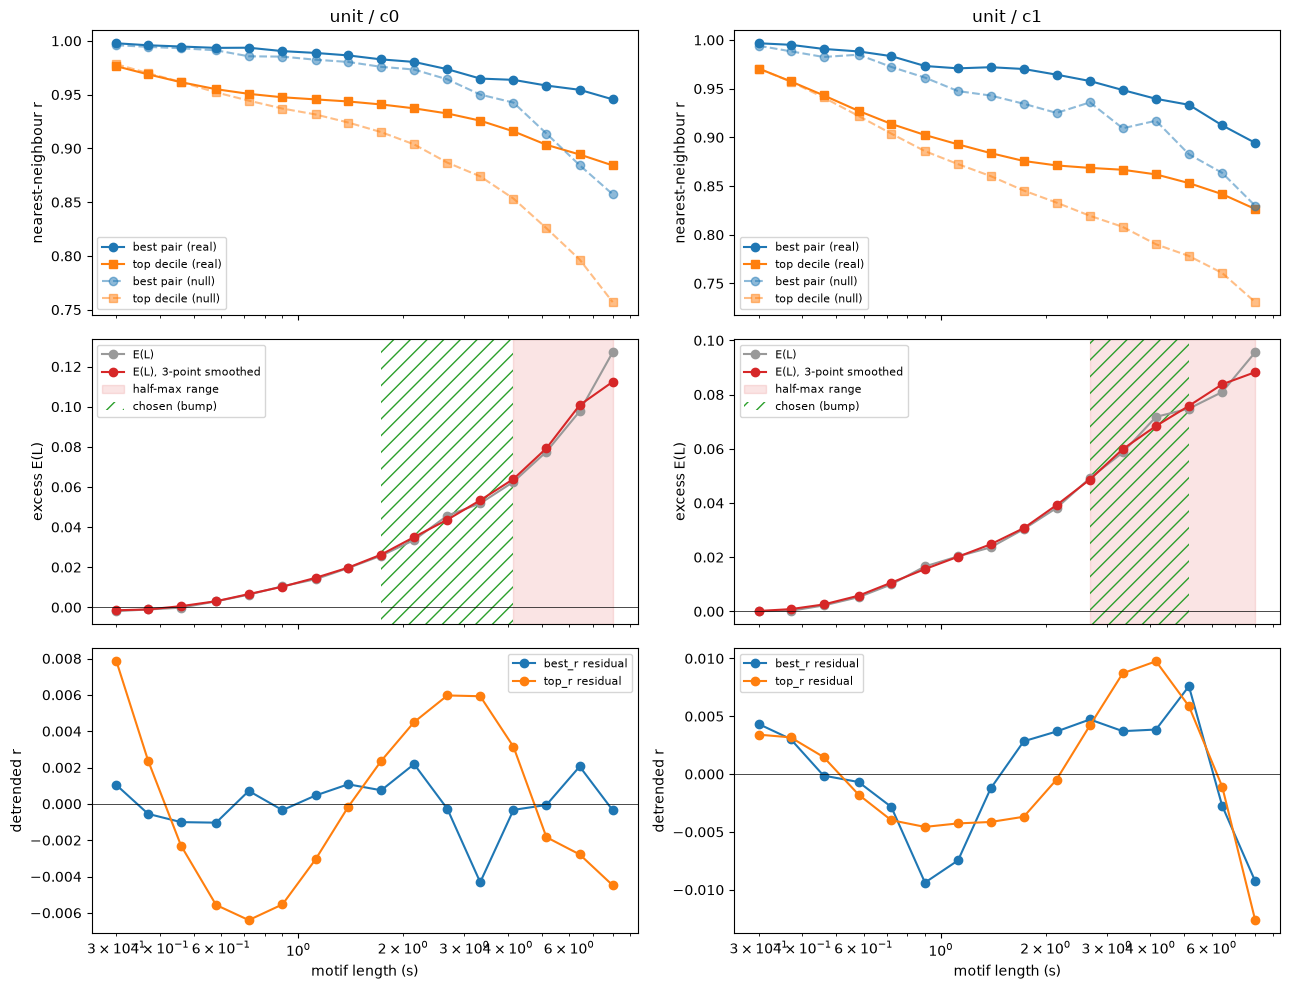

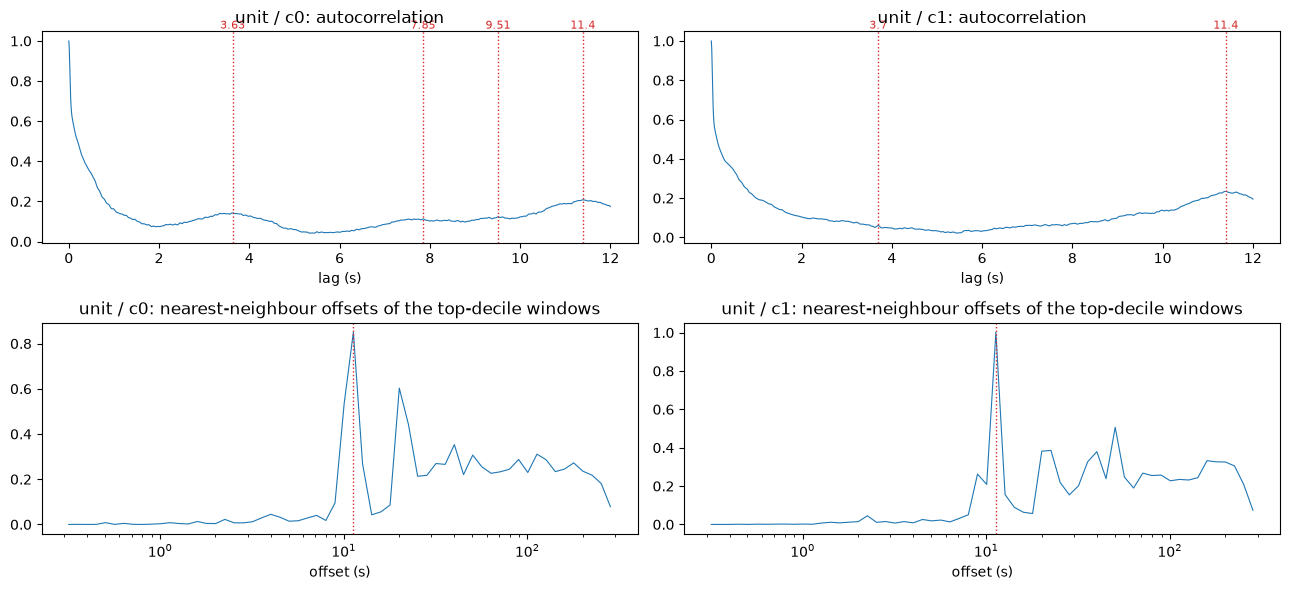

,E peak (s),E peak,half-max range (s),localized,E accepted,support,bump range (s),ACF periods (s),offset periods (s),chosen (s),source,threshold r,prior overlap
feature,,,,,,,,,,,,,
c0,8.0,0.112,4.15-8,False,False,best_r bump at 6.43 s; period 3.63 s; period 1...,1.73-4.15,"3.63, 11.4, 7.85, 9.51",11.3,1.73-4.15,bump,0.887,True
c1,8.0,0.088,2.68-8,False,False,"top_r bump at 4.15 s; best_r bump at 2.68, 5.1...",2.68-5.16,"11.4, 3.7",11.3,2.68-5.16,bump,0.799,True


In [6]:
run_band("unit")

## Phrase band (5–120 s)

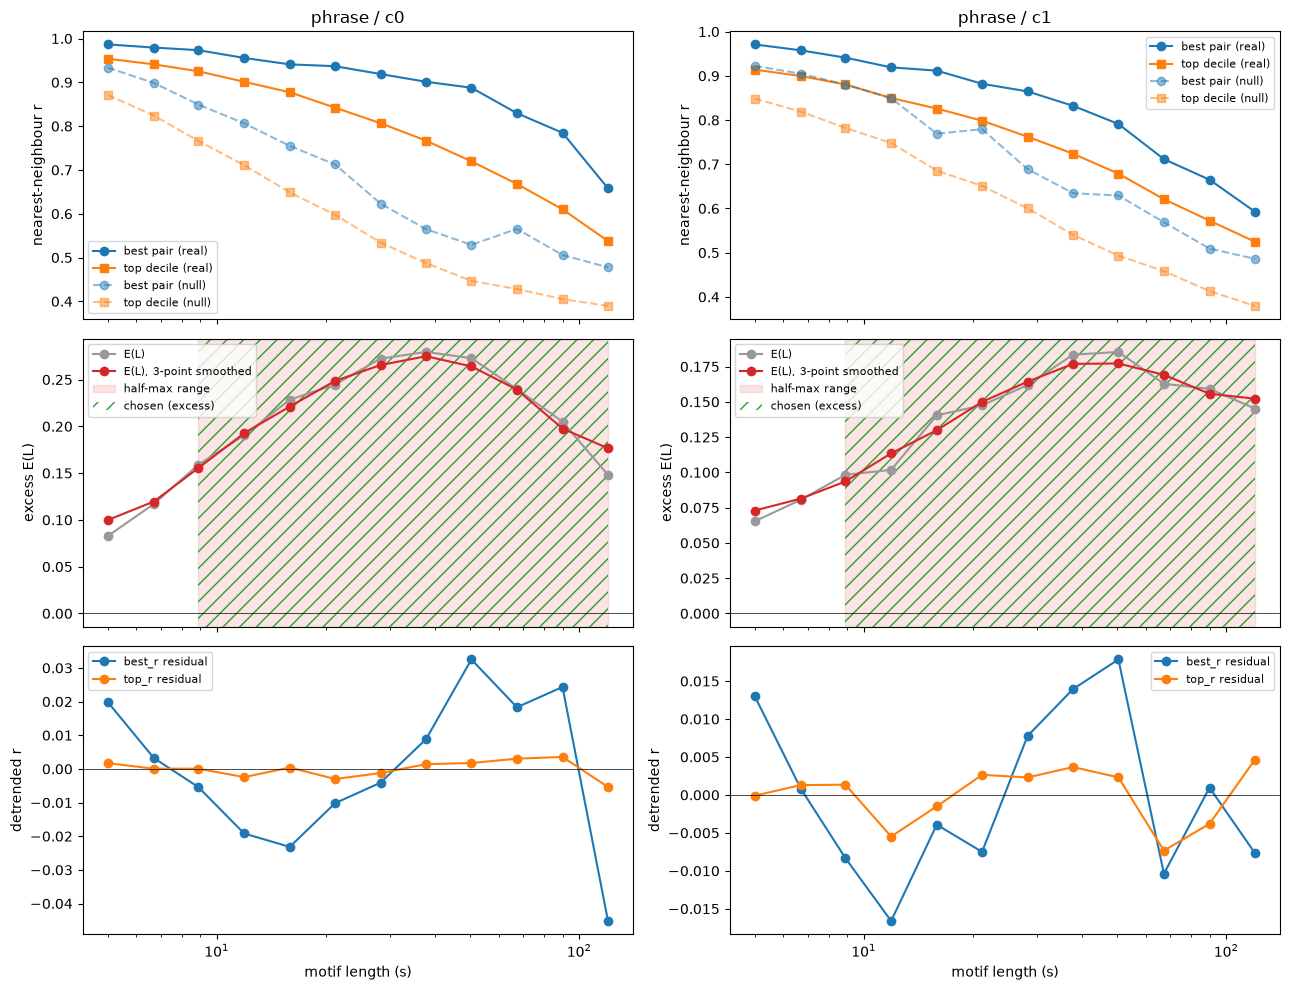

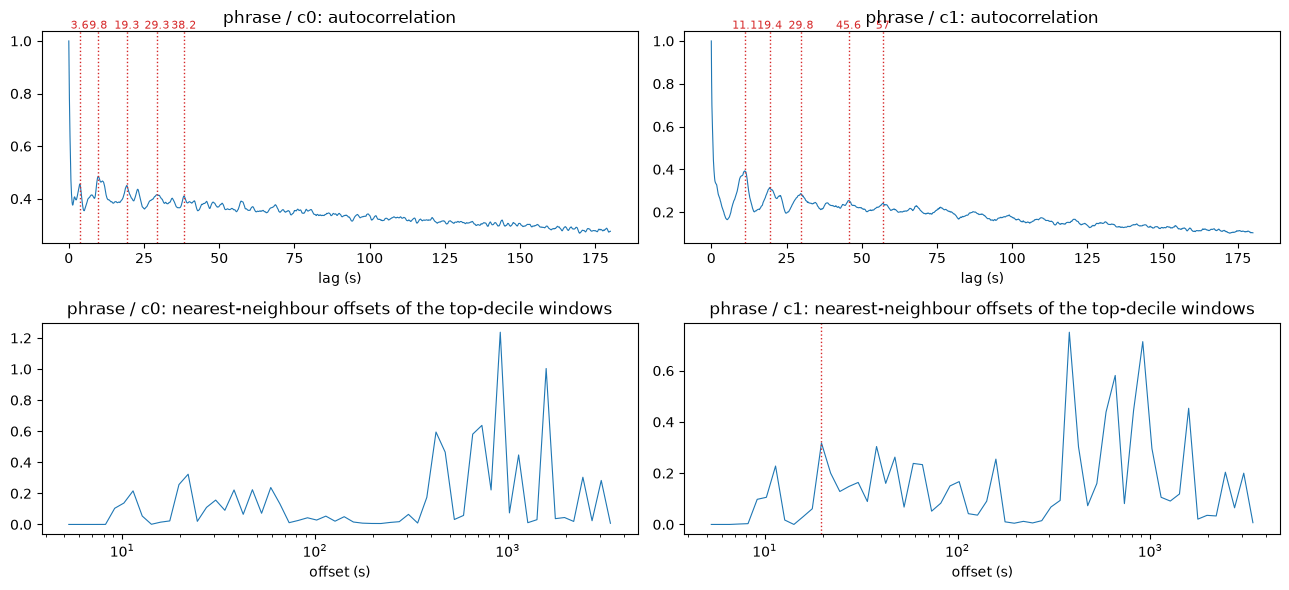

,E peak (s),E peak,half-max range (s),localized,E accepted,support,bump range (s),ACF periods (s),offset periods (s),chosen (s),source,threshold r,prior overlap
feature,,,,,,,,,,,,,
c0,37.8,0.275,8.9-120,True,True,"top_r bump at 15.9, 89.9 s; best_r bump at 50....",15.9-15.9,"9.8, 3.6, 19.3, 29.3, 38.2",,8.9-120,excess,0.511,None
c1,50.4,0.177,8.9-120,True,True,"top_r bump at 8.9, 21.2, 37.8 s; best_r bump a...",21.2-50.4,"11.1, 19.4, 29.8, 45.6, 57",19.7,8.9-120,excess,0.571,None


In [7]:
run_band("phrase")

## Theme band (1–8 min)

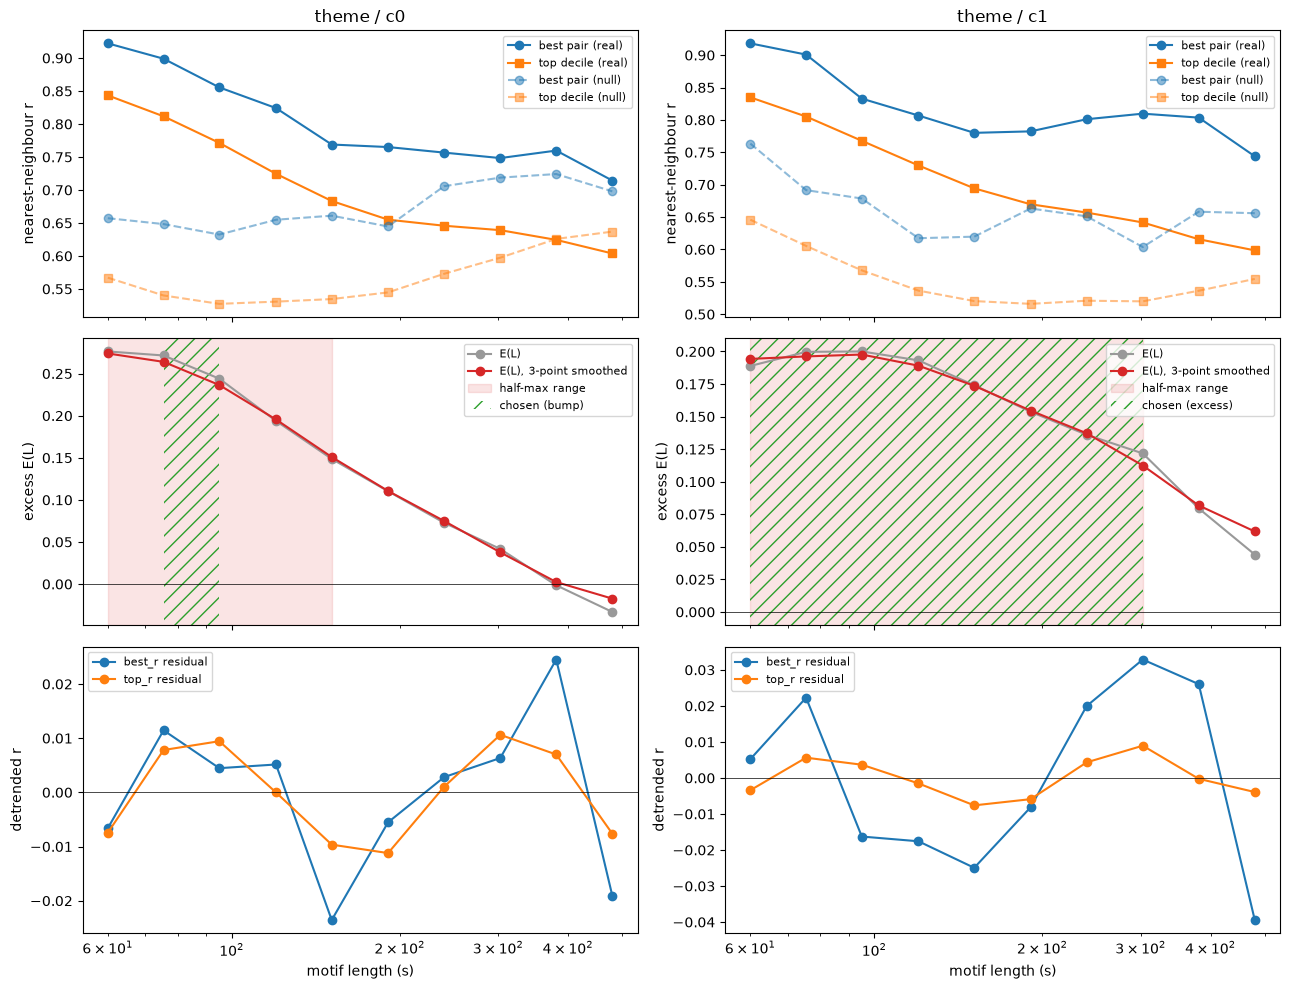

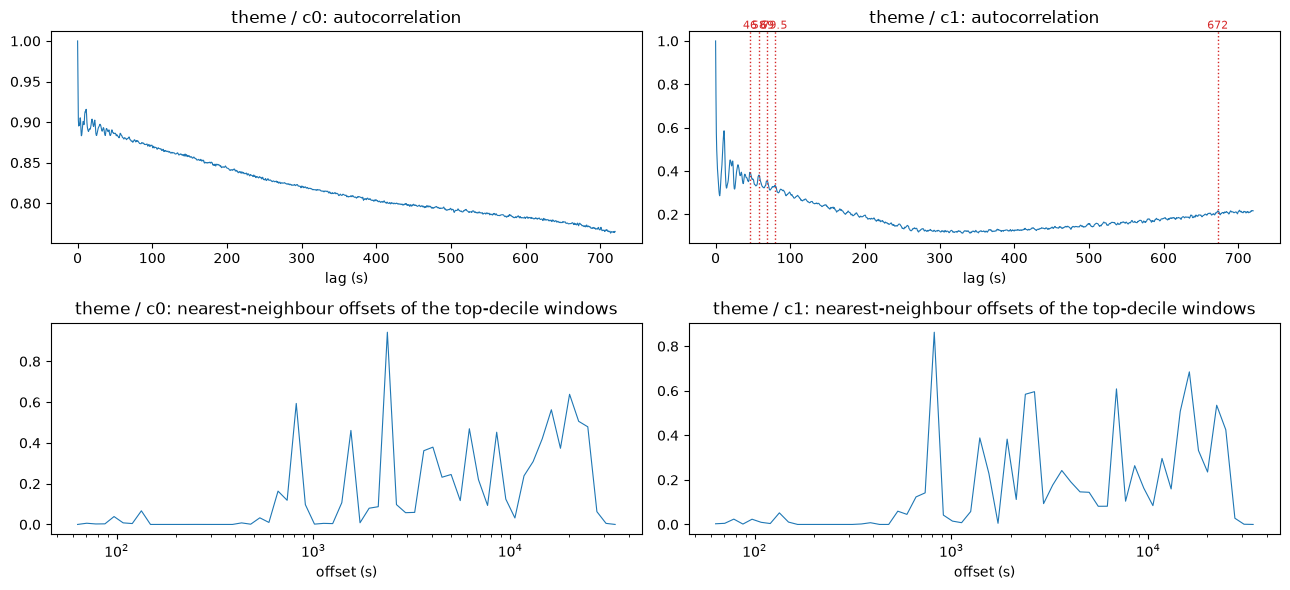

,E peak (s),E peak,half-max range (s),localized,E accepted,support,bump range (s),ACF periods (s),offset periods (s),chosen (s),source,threshold r,prior overlap
feature,,,,,,,,,,,,,
c0,60.0,0.274,60-151,False,False,"top_r bump at 95 s; best_r bump at 75.5, 120 s...",75.5-95,,,75.5-95,bump,0.534,None
c1,95.0,0.198,60-302,True,True,"top_r bump at 75.5, 302.5 s; best_r bump at 75...",75.5-95,"46, 58, 69, 79.5, 672",,60-302,excess,0.528,None


In [8]:
run_band("theme")

## Song band (5–25 min)

First the regularity criterion: for the best-matching pair at each length, its copies over the night (as in the
PDF). The song period is taken from the strongest autocorrelation peak within 1.5× of the 10–20 min prior
(or the median song length of 12.4 min if there is none). A length passes if its copies recur every
period ± 25%, the gaps vary by at most 30% (coefficient of variation), and no stretch of the night longer than
1.5 periods has no copy.

In [9]:
SONG = BANDS["song"]
REG = {}
for name, col in FEATURES.items():
    path = f"whale_song_regularity_{name}.csv"
    T1 = band_segments(col, SONG)[0]
    if os.path.exists(path):
        reg = pd.read_csv(path)
    else:
        ms = np.round(SONG["lengths_s"] * SONG["rate"]).astype(int)
        reg = w.song_regularity(T1, ms, SONG["rate"])
        reg.to_csv(path, index=False)
    acf = w.autocorrelation(T1, 2500)
    peaks = w.period_peaks(np.arange(2501.0), acf, prominence=0.01, min_lag_s=SONG["prior"][0] / 1.5)
    peaks = [p for p in peaks if p[0] <= SONG["prior"][1] * 1.5]
    period = peaks[0][0] if peaks else 744.0
    lo, hi, ok = w.regular_range(reg, period)
    REG[name] = dict(table=reg.assign(regular=ok), period=period, range=(lo, hi))
    print(f"{name}: song period {period:.0f} s ({period / 60:.1f} min); regular lengths: "
          + ("none" if lo is None else f"{lo / 60:.0f}-{hi / 60:.0f} min"))
    display(REG[name]["table"].round(3))

c0: song period 744 s (12.4 min); regular lengths: 7-9 min


,length_s,seed_min,seed_r,threshold,copies,median_gap_min,gap_cv,max_stretch_min,coverage,regular
0,300.0,114.117,0.792,0.20,69,8.258,0.373,17.433,0.568,False
1,360.0,113.317,0.805,0.17,57,10.875,0.294,18.767,0.568,False
2,420.0,112.317,0.798,0.06,58,10.533,0.257,14.833,0.668,True
3,480.0,111.600,0.772,0.03,54,11.033,0.212,16.850,0.715,True
4,540.0,110.633,0.735,0.03,51,11.592,0.201,17.033,0.757,True
5,600.0,185.700,0.710,0.01,46,12.250,0.274,30.433,0.760,False
6,660.0,185.150,0.713,0.01,44,12.767,0.255,29.783,0.799,False
7,720.0,184.200,0.711,0.01,42,12.850,0.371,43.850,0.826,False
8,780.0,183.700,0.688,0.01,40,12.867,0.348,41.333,0.843,False
9,840.0,185.317,0.678,0.01,37,13.600,0.416,50.733,0.831,False


c1: song period 788 s (13.1 min); regular lengths: 5-10 min


,length_s,seed_min,seed_r,threshold,copies,median_gap_min,gap_cv,max_stretch_min,coverage,regular
0,300.0,114.133,0.844,0.26,56,11.133,0.280,15.800,0.467,True
1,360.0,113.300,0.845,0.23,53,11.967,0.258,17.317,0.529,True
2,420.0,112.633,0.823,0.22,52,12.050,0.246,17.333,0.604,True
3,480.0,290.283,0.794,0.22,49,12.583,0.234,18.517,0.647,True
4,540.0,289.433,0.771,0.01,51,11.908,0.217,20.317,0.756,False
5,600.0,289.100,0.759,0.09,47,12.842,0.168,17.517,0.778,True
6,660.0,287.917,0.741,0.01,46,12.750,0.188,20.767,0.834,False
7,720.0,286.750,0.706,0.01,44,13.200,0.194,20.767,0.863,False
8,780.0,294.150,0.706,0.01,40,13.217,0.267,28.067,0.839,False
9,840.0,293.517,0.711,0.01,37,13.800,0.265,28.067,0.832,False


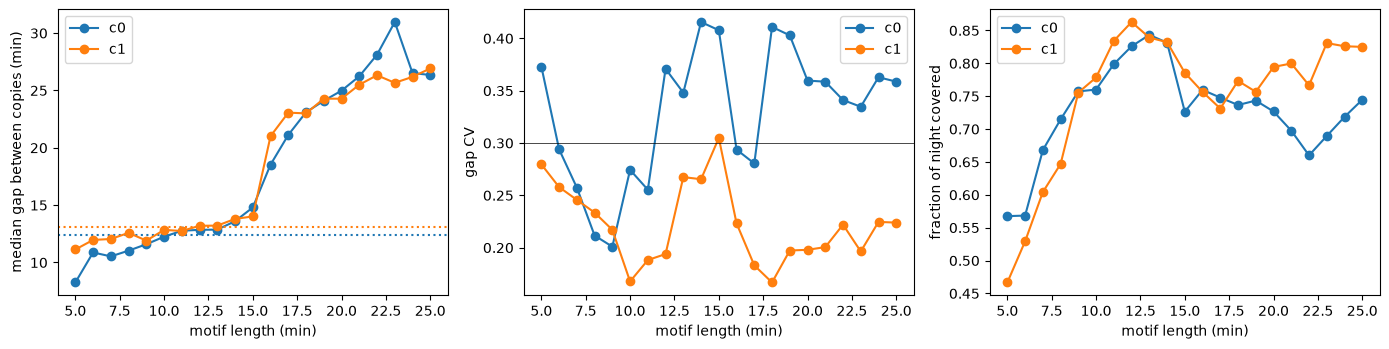

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for name in FEATURES:
    t = REG[name]["table"]
    axes[0].plot(t["length_s"] / 60, t["median_gap_min"], "o-", label=name)
    axes[1].plot(t["length_s"] / 60, t["gap_cv"], "o-", label=name)
    axes[2].plot(t["length_s"] / 60, t["coverage"], "o-", label=name)
    axes[0].axhline(REG[name]["period"] / 60, ls=":", c=axes[0].lines[-1].get_color())
axes[0].set_ylabel("median gap between copies (min)")
axes[1].set_ylabel("gap CV")
axes[1].axhline(0.3, c="k", lw=0.5)
axes[2].set_ylabel("fraction of night covered")
for ax in axes:
    ax.set_xlabel("motif length (min)")
    ax.legend()
fig.tight_layout()
plt.show()

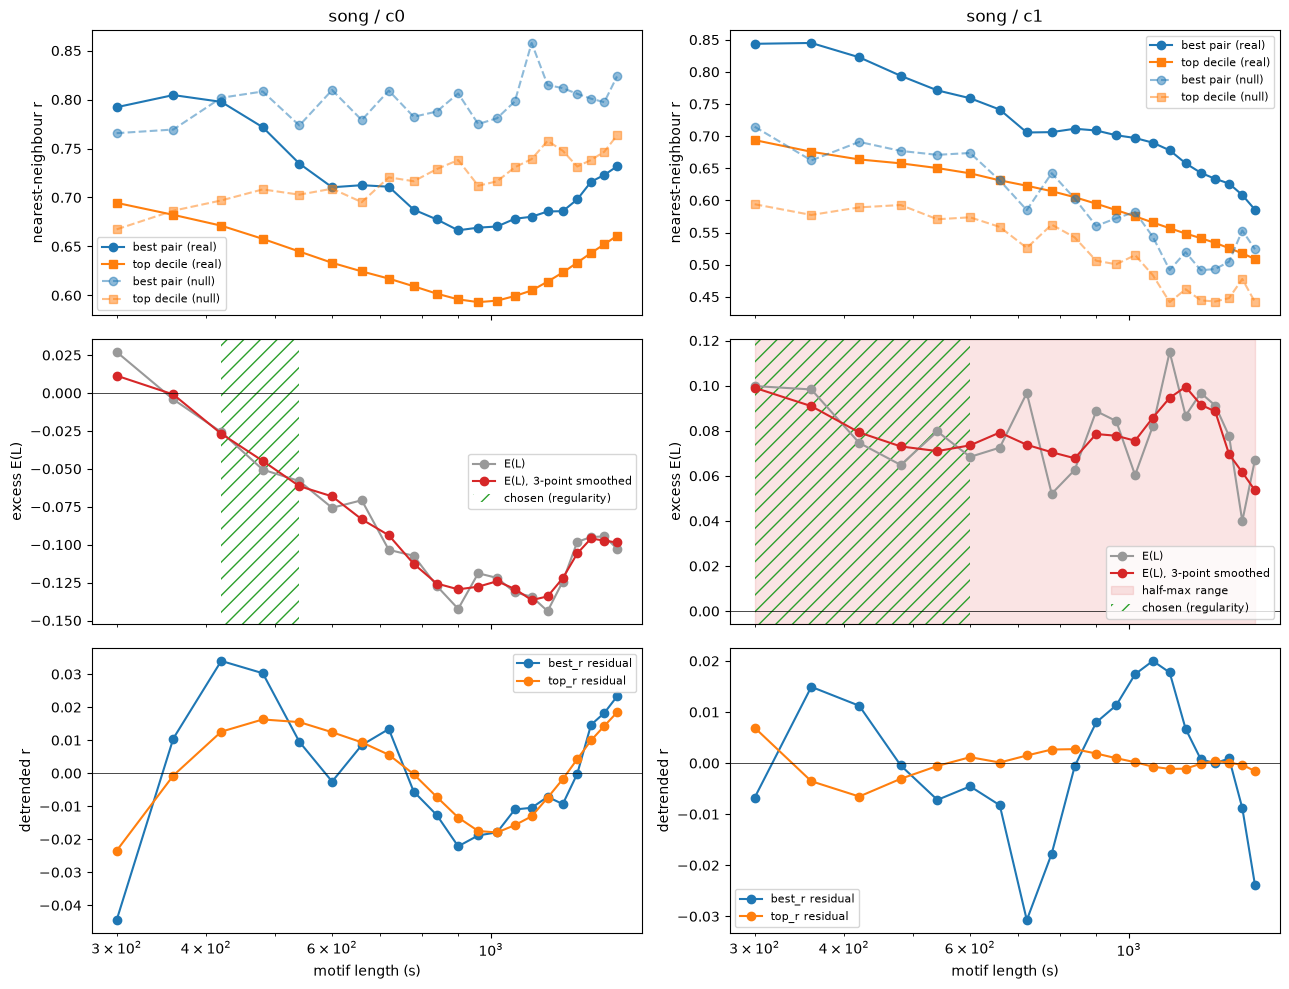

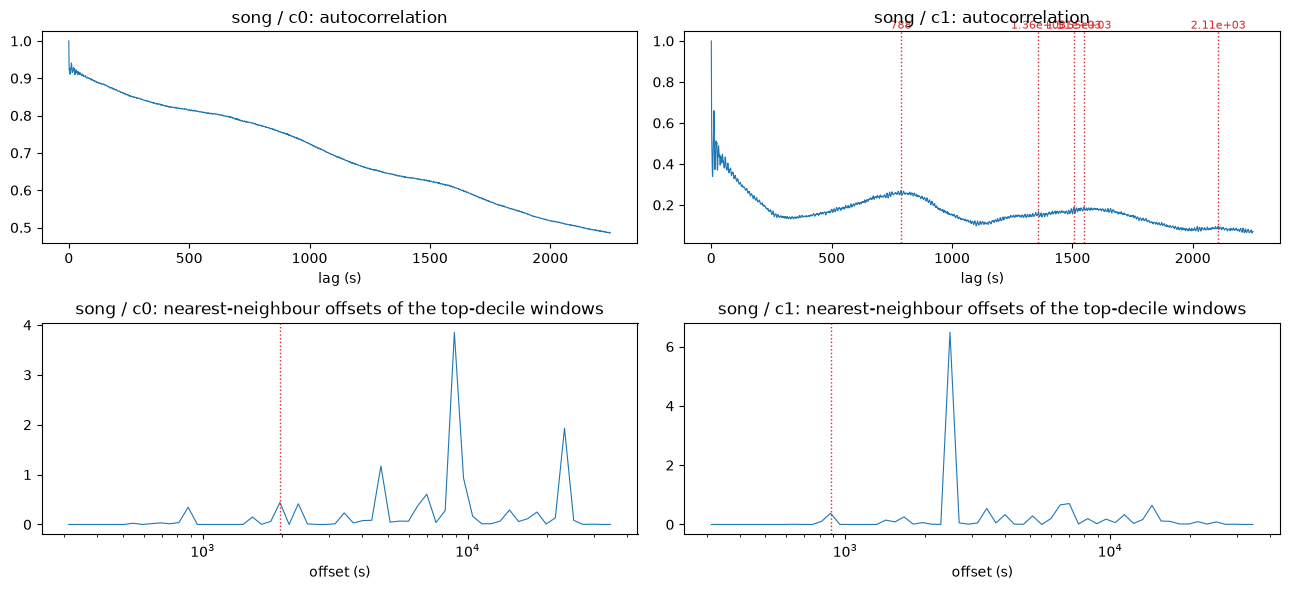

,E peak (s),E peak,half-max range (s),localized,E accepted,support,bump range (s),ACF periods (s),offset periods (s),chosen (s),source,threshold r,prior overlap
feature,,,,,,,,,,,,,
c0,300.0,0.011,NaN,None,False,peak excess 0.011 < 0.02,NaN,,1.96e+03,420-540,regularity,0.708,False
c1,1200.0,0.099,300-1.5e+03,False,False,"top_r bump at 600, 840, 1320 s; best_r bump at...",1.32e+03-1.38e+03,"788, 1.55e+03, 1.51e+03, 1.36e+03, 2.11e+03",881,300-600,regularity,0.589,True


In [11]:
run_band("song", REG)

## Chosen ranges

`source` says which criterion decided: `excess` (half-maximum width of $E(L)$, supported by a bump or a period),
`regularity` (song level), or `fallback` (no support, so the initial guess is used).

In [12]:
def to_py(v):
    if isinstance(v, (np.floating, np.integer)):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [to_py(x) for x in v]
    return v


KEYS = ["lo_s", "hi_s", "rate_hz", "threshold_r", "source", "supported", "prior", "prior_overlap",
        "peak_s", "peak_excess", "accepted", "localized", "flat", "at_edge", "e_lo_s", "e_hi_s",
        "bump_range_s", "support", "acf_periods_s", "offset_periods_s"]
ranges = {"meta": {"features_cache": "whale_mfcc_193500_100hz.npz", "frame_rate": FRAME_RATE,
                   "feature_columns": FEATURES, "offset_014845_sec": OFFSET_SEC}}
for name in FEATURES:
    ranges[name] = {}
    for band in BANDS:
        d = RESULTS[band][name]["decision"]
        ranges[name][band] = {k: to_py(d.get(k)) for k in KEYS}
    ranges[name]["song"]["song_period_s"] = to_py(REG[name]["period"])
with open("whale_length_ranges.json", "w") as f:
    json.dump(ranges, f, indent=2)

pd.DataFrame([
    {"feature": name, "level": band, "range (s)": f"{d['lo_s']:.3g}-{d['hi_s']:.3g}", "source": d["source"],
     "rate (Hz)": d["rate_hz"], "threshold r": round(d["threshold_r"], 3), "prior overlap": d["prior_overlap"]}
    for name in FEATURES for band, d in ranges[name].items()
]).set_index(["feature", "level"])

range (s)      source  rate (Hz)  threshold r prior overlap
feature level                                                              
c0      unit    1.73-4.15        bump        100        0.887          True
        phrase    8.9-120      excess         10        0.511          None
        theme     75.5-95        bump          2        0.534          None
        song      420-540  regularity          1        0.708         False
c1      unit    2.68-5.16        bump        100        0.799          True
        phrase    8.9-120      excess         10        0.571          None
        theme      60-302      excess          2        0.528          None
        song      300-600  regularity          1        0.589          True

## Reading the results

- **Alignment.** The 37.5-minute file starts at 22,424.5 s (6 h 13 min 44.5 s) into the 10-hour file; the features
  of the two files agree with r > 0.99 over the whole overlap.
- **One broad excess maximum.** Joined across the bands, $E(L)$ rises from ~0 at 0.3 s, peaks at **~40–100 s**
  (phrase band: 38 s for c0, 50 s for c1; theme band: 95 s for c1) and falls toward the song lengths. Excess
  repetition is strongest for chunks of about a minute.
- **Units.** $E(L)$ has no peak of its own below 8 s, so the unit range comes from the residual bump:
  ~1.7–4.2 s (c0) and ~2.7–5.2 s (c1). That overlaps the 1–3 s prior; a motif window includes the unit plus a
  little of the gap around it.
- **Phrase period.** The sharpest periodicity in the data is the **~11.3 s** offset between a chunk and its best
  match (unit band, both features), echoed by autocorrelation peaks at ~10–11 s and its multiples (~20, ~30, ~40 s)
  in the phrase band. Read as: phrases of ~11 s, repeated several times in a row (themes); the excess maximum at
  40–50 s then covers about four repeated phrases.
- **Songs.** c0 shows no excess at song lengths (its slow loudness changes, which the surrogate keeps, dominate).
  c1 has a flat $E(L)$, but its autocorrelation peaks at 788 s (13.1 min) and copies of 5–10 min motifs recur
  every 11–13 min with regular gaps, matching the PDF's 12–14 min song cycle and the 10–20 min prior.
- Phase 2 (`Whale_Song_Multiscale_Forward_Motifs.ipynb`) uses these ranges, with the null's top-decile correlation
  at each length as the minimum correlation for a detection.